# 03 - Baseline : régression logistique (TF-IDF de n-grammes de caractères)

**Entrée :** `data/processed/train.csv` et `val.csv` · **Code réutilisable :** `src/models/baseline_logreg.py`, `src/evaluation/metrics.py`

**Objectif.** Construire le **premier modèle de référence** (baseline) et mesurer ses scores sur la **validation CSIC**.


**Rappels importants**
- Classe positive = **injection (1)**. Mesures prioritaires : **Recall** et **F1** de cette classe. L'Accuracy n'est jamais citée seule.
- Le jeu de test **Juice Shop n'est pas touché ici**. Tout le réglage se fait sur la validation CSIC.

## 0. Préparation


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

from src.models.baseline_logreg import LogRegDetector, manual_features
from src.evaluation.metrics import (
    compute_metrics, format_report, best_threshold, plot_confusion_matrix,
)

pd.set_option("display.max_colwidth", 140)

## 1. Charger train et validation

On lit les deux fichiers créés par le notebook 02. Chaque ligne a un `text` (la requête normalisée)
et un `label` (0 = normal, 1 = injection). Le **train** sert à apprendre, la **validation** à mesurer.

In [2]:
train = pd.read_csv(ROOT / "data" / "processed" / "train.csv")
val = pd.read_csv(ROOT / "data" / "processed" / "val.csv")
print("train :", train.shape, "| injections :", f"{train['label'].mean():.1%}")
print("val   :", val.shape, "| injections :", f"{val['label'].mean():.1%}")
train.head(3)

train : (10676, 2) | injections : 27.7%
val   : (2669, 2) | injections : 27.7%


,text,label
0,get /tienda1/publico/autenticar.jsp?modo=entrar&login=ardavan&pwd=4l09o636a&remember=on&b1=entrar,0
1,get /tienda1/publico/registro.jsp?modo=registro&login=lombardo&password=enris6rar&nombre=santos&apellidos=gaja&email=karelsen_cisar@sera...,0
2,get /tienda1/publico/registro.jsp?modo=registro&login=sheree&password=baladora&nombre=atos&apellidos=mató farriols&email=pierfederici@so...,0


## 2. Comment le texte devient des nombres (TF-IDF de n-grammes de caractères)

 Un modèle ne lit pas du texte. On découpe chaque requête en **morceaux de 2 à 5 caractères**
(n-grammes) et on compte leur importance (**TF-IDF** : un morceau rare mais présent dans la requête pèse plus
qu'un morceau présent partout). Pourquoi des caractères et pas des mots ? Une injection se reconnaît à de
petits motifs (`' or`, `--`, `<scr`, `union`), qui survivent aux changements de casse, d'espaces ou d'encodage.
On ajoute 4 **features manuelles** : longueur, nombre de caractères spéciaux, proportion, nombre de paramètres.

In [4]:
exemple = "get /app/search?q=' or 1=1 --"
# les n-grammes de caractères de longueur 4 de cet exemple
print([exemple[i:i + 4] for i in range(8, 20)])

# les 4 features manuelles : [longueur, nb spéciaux, proportion spéciaux, nb paramètres]
print(manual_features([exemple, "get /tienda1/publico/index.jsp"]).round(2))

['/sea', 'sear', 'earc', 'arch', 'rch?', 'ch?q', 'h?q=', "?q='", "q=' ", "=' o", "' or", ' or ']
[[29.    7.    0.24  1.  ]
 [30.    3.    0.1   1.  ]]


**Interprétation.** Les morceaux comme `' or`, `or 1`, `1=1 ` apparaissent dans les attaques, très rarement dans
le trafic normal : c'est ce que le modèle exploitera. La requête d'attaque a une proportion de caractères
spéciaux nettement plus forte que la requête normale (deuxième tableau).

## 3. Entraîner le modèle

`LogRegDetector().fit(...)` apprend sur le **train seulement** : le vocabulaire TF-IDF, l'échelle des
features manuelles et la régression logistique. `class_weight="balanced"` donne plus de poids aux injections (≈ 28 %
des données) pour qu'elles ne soient pas « noyées » par les requêtes normales.

In [5]:
model = LogRegDetector().fit(train["text"], train["label"])
print("n-grammes appris :", len(model.tfidf.vocabulary_))

n-grammes appris : 50000


## 4. Scores sur la validation (seuil 0,5)

 Le modèle donne pour chaque requête une **probabilité d'injection**. Avec le seuil 0,5 : plus de 0,5 =
injection. On calcule Precision, Recall, F1, Accuracy, taux de fausses alarmes et AUC, puis la **matrice de confusion**.
- **Recall** = parmi les vraies injections, combien on en détecte.
- **Precision** = parmi les alertes, combien sont de vraies injections.

=== LogReg - validation CSIC (seuil 0.5) ===
Precision (injection) : 0.9764
Recall    (injection) : 0.9500   <- mesure prioritaire
F1        (injection) : 0.9630
Accuracy              : 0.9798   (jamais seule)
Taux de fausses alarmes: 0.0088
ROC-AUC               : 0.9979
Matrice : TN=1912  FP=17  FN=37  TP=703


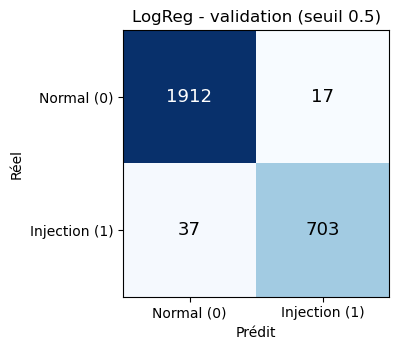

In [6]:
val_score = model.predict_proba(val["text"])
m05 = compute_metrics(val["label"], (val_score >= 0.5).astype(int), val_score)
print(format_report(m05, "LogReg - validation CSIC (seuil 0.5)"))
plot_confusion_matrix(m05, "LogReg - validation (seuil 0.5)")
plt.show()

**Interprétation.** Le modèle détecte **95,0 % des injections** (Recall 0,950) et **97,6 %** de ses alertes sont
justes (Precision 0,976), pour un **F1 de 0,963**. Sur 740 injections de validation : 703 détectées (TP) et
**37 manquées** (FN). Sur 1 929 requêtes normales : 17 fausses alarmes seulement (0,9 %). L'AUC de 0,998 montre que les
scores séparent presque parfaitement les deux classes ; les erreurs viennent donc surtout de quelques cas difficiles.


## 5. Choisir le seuil sur la validation
 Le seuil 0,5 n'est pas sacré. `best_threshold` cherche celui qui maximise le F1 **sur la validation**
. Une fois choisi, il est **figé**. On trace aussi la courbe Precision-Recall.

Meilleur seuil : 0.501 | F1 = 0.963


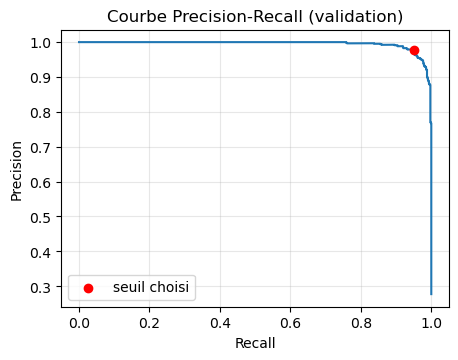

In [7]:
best = best_threshold(val["label"], val_score)
print("Meilleur seuil :", round(best["threshold"], 3), "| F1 =", round(best["f1"], 4))

p, r, t = precision_recall_curve(val["label"], val_score)
plt.figure(figsize=(5, 3.6))
plt.plot(r, p)
plt.scatter([best["recall"]], [best["precision"]], color="red", zorder=3, label="seuil choisi")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Courbe Precision-Recall (validation)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Interprétation.** Le seuil optimal est **≈ 0,50** : il est quasiment identique au seuil par défaut, donc le
modèle est déjà bien calibré et le réglage n'apporte rien. La courbe reste proche du coin en haut à droite
(Precision et Recall élevés ensemble). Note honnête : choisir le seuil et mesurer sur la même validation est un peu
optimiste ; ici l'écart est nul, donc sans conséquence. Si on veut détecter *plus* d'attaques, on peut baisser le
seuil (le Recall monte, la Precision baisse) 

## 6. Analyse des erreurs

On regarde les requêtes que le modèle **rate** (faux négatifs : injection non détectée) et celles qu'il
**signale à tort** (faux positifs). Comprendre les erreurs vaut mieux qu'un chiffre.

In [8]:
seuil = best["threshold"]
pred = (val_score >= seuil).astype(int)
fn = val[(val["label"] == 1) & (pred == 0)]
fp = val[(val["label"] == 0) & (pred == 1)]
print(f"Faux négatifs : {len(fn)} | Faux positifs : {len(fp)}\n")

print("--- 5 injections MANQUEES (extrait autour du caractère suspect) ---")
for t in fn["text"].head(5):
    i = t.find("'")
    print(" -", t[max(0, i - 35): i + 35] if i >= 0 else t[:80])

print("\n--- 5 fausses alarmes ---")
for t in fp["text"].head(5):
    print(" -", t[-90:])

# combien de faux négatifs ne contiennent qu'une simple apostrophe (sonde faible) ?
seul_quote = fn["text"].map(lambda s: "'" in s and not any(k in s for k in ["select", "union", "<", "--", " or ", "drop"]))
print(f"\nFaux négatifs avec une simple apostrophe sans mot SQL : {int(seul_quote.sum())} / {len(fn)}")

Faux négatifs : 37 | Faux positifs : 17

--- 5 injections MANQUEES (extrait autour du caractère suspect) ---
 - ti@casablancabeach.gob&dni=86771416'&direccion=c/ reyes magos 130, &ci
 - do=registro&login=bhasin&password=n'en&nombre=saiguen&apellidos=pederc
 - o&login=gawargy&password=esquemátic'a&nombre=diógenes&apellidos=marcha
 - =perier@chevrolet-volt.in&dni=94097'81l&direccion=calle alfonso onceno
 - modo=entrar&login=chinh&pwd=za1pa8i'm,osnas&remember=off&b1=entrar

--- 5 fausses alarmes ---
 -  /tienda1/publico/autenticar.jsp?modo=entrar&login=bi-jun&pwd=remedo&remember=on&b1=entrar
 -  191 8-h&ciudad=omañas, las&cp=50259&provincia=barcelona&ntc=0076747388160328&b1=registrar
 - iudad=villamediana de iregua&cp=39738&provincia=zaragoza&ntc=2840005774765443&b1=registrar
 -  /tienda1/publico/autenticar.jsp modo=entrar&login=tonny&pwd=*aquele&remember=on&b1=entrar
 - -a&ciudad=villahermosa del río&cp=34170&provincia=burgos&ntc=1059928902417697&b1=registrar

Faux négatifs avec une simp

**Interprétation.** Parmi les 37 injections manquées, **33** sont des **sondes très faibles** : une seule apostrophe
glissée au milieu d'un champ de formulaire normal (`dni=94097'81l`, `pwd=za1pa8i'm,osnas`). Ce n'est pas une charge
SQL complète, c'est ce qui les rend difficiles à distinguer d'une saisie normale. Les fausses alarmes sont des
requêtes avec des caractères `-`, `*` ou `,` dans une adresse ou un login ou un mot de passe. Conclusion : les erreurs sont
**explicables**, et un modèle plus contextuel (Random Forest, DistilBERT) pourrait aider sur ces cas limites.

## 7. Qu'est-ce que le modèle a appris ? (coefficients)

Dans une régression logistique, chaque n-gramme a un **coefficient** : positif = pousse vers « injection »,
négatif = pousse vers « normal ». On affiche les 12 plus forts dans chaque sens pour vérifier que le modèle apprend
de vrais signaux et non des artefacts.

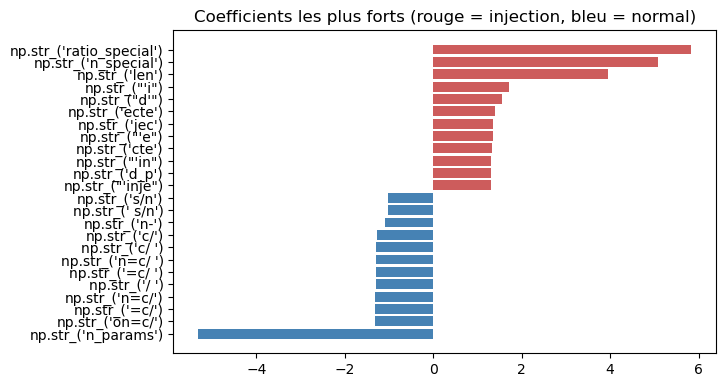

Poussent vers INJECTION : ['ratio_special', 'n_special', 'len', "'i", "d'", 'ecte', 'jec', "'e", 'cte', "'in", 'd_p', "'inje"]


In [9]:
noms = np.array(list(model.tfidf.get_feature_names_out()) + ["len", "n_special", "ratio_special", "n_params"])
coef = model.clf.coef_[0]
ordre = np.argsort(coef)
top_neg, top_pos = ordre[:12], ordre[-12:]

fig, ax = plt.subplots(figsize=(7, 4.2))
idx = list(top_neg) + list(top_pos)
ax.barh([repr(noms[i]) for i in idx], coef[idx], color=["steelblue"] * 12 + ["indianred"] * 12)
ax.set_title("Coefficients les plus forts (rouge = injection, bleu = normal)")
plt.show()
print("Poussent vers INJECTION :", [str(noms[i]) for i in top_pos[::-1]])

## 8. Vérification d'un artefact : le mot « injected »

Les n-grammes `injec`, `ecte`, `d_p` suggèrent que certaines attaques CSIC contiennent le mot littéral
`injected`. Si c'est fréquent, le modèle peut « tricher » en cherchant ce mot. On compte.

In [10]:
tout = pd.concat([train, val])
m = tout["text"].str.contains("injected")
print("Requêtes contenant 'injected' :", int(m.sum()), "| classes :", tout[m]["label"].value_counts().to_dict())
print(f"Part des injections concernées : {m.sum() / (tout['label'] == 1).sum():.1%}")

Requêtes contenant 'injected' : 134 | classes : {1: 134}
Part des injections concernées : 3.6%


- Le mot `injected` n'apparaît que dans des **injections** (134 cas, ~3,6 % des 3 701 injections),
jamais dans les requêtes normales.

## 9. Sauvegarde

Le script `python -m src.models.baseline_logreg` fait tout ce notebook en une commande et sauvegarde
le modèle (`models/logreg_baseline.joblib`, non versionné), les scores (`reports/logreg_val_metrics.json`) et la
matrice de confusion (`reports/figures/logreg_val_confusion.png`).

In [12]:
import json
metriques = json.load(open(ROOT / "reports" / "logreg_val_metrics.json"))
{k: round(v, 4) for k, v in metriques["threshold_best"].items() if k in ["precision", "recall", "f1", "accuracy", "roc_auc"]}

{'precision': 0.9764,
 'recall': 0.95,
 'f1': 0.963,
 'accuracy': 0.9798,
 'roc_auc': 0.9979}

## 10. Conclusion

| Mesure (injection, validation CSIC) | Valeur |
|---|---|
| Precision | 0,9764 |
| **Recall** | **0,950** |
| **F1** | **0,963** |
| Accuracy (jamais seule) | 0,9798 |
| Fausses alarmes | 0,9 % |

- La baseline est **solide** : 95 % des injections détectées avec très peu de fausses alarmes.
- Les 37 injections manquées sont surtout des sondes très faibles (une apostrophe isolée).
- Un artefact CSIC (`injected`) existe mais touche peu de lignes (~3,6 %).
  

